## Preliminary

Skript to generate a figure similar to Fig. 9 from Lykkegaard 2023.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import arviz as az

from scipy.integrate import solve_ivp

import tinyDA as tda

In [2]:
np.random.seed(987)

In [3]:
class PredatorPreyModel: 
    def __init__(self, datapoints):
        
        # set the timesteps, where we are collecting the model output
        self.datapoints = datapoints
        
        # set the span of the integration.
        self.t_span = [0, self.datapoints[-1]]
        
    def dydx(self, t, y, a, b, c, d):
        # Lotka-Volterra Model model, see e.g. https://en.wikipedia.org/wiki/Lotka%E2%80%93Volterra_equations
        return np.array([a*y[0] - b*y[0]*y[1], c*y[0]*y[1] - d*y[1]])

    def __call__(self, parameters):
        
        # extract the parameters, and take the exponential to keep them positive
        P_0, Q_0, a, b, c, d = np.exp(parameters)
        
        # solve the initial value problem.
        self.y = solve_ivp(lambda t, y: self.dydx(t, y, a, b, c, d), self.t_span, np.array([P_0, Q_0]), t_eval=self.datapoints) 
        
        # return the results, only if the integration succeeded.
        if self.y.success:
            return self.y.y.flatten(), self.y.y[1,:].mean()
        else:
            return np.nan, np.nan         # (model output, QoI)

In [5]:
class ReducedPredatorPreyModel(PredatorPreyModel):
    def __init__(self, datapoints, free, fixed_parameters):
        super().__init__(datapoints)

        # which of the six (log-)parameters are sampled, and the values of the others
        self.free = free
        self.fixed_parameters = fixed_parameters

    def __call__(self, parameters):
        full_parameters = self.fixed_parameters.copy()
        full_parameters[self.free] = parameters
        return super().__call__(full_parameters)

In [7]:
names = ['N_0', 'P_0', 'a', 'b', 'c', 'd']

# set the true parameters
P_0 = 10
Q_0 = 5
a = 3.0
b = 0.7
c = 0.2
d = 1.0

# collect the parameters in a vector and take the logarithm.
# we sample the log of the parameters and take the exponential
# inside the model to keep the parameters positive.
true_parameters_all = np.log(np.array([P_0, Q_0, a, b, c, d]))

# which parameters are sampled; here the predation parameters a and b
free = [2, 3]
true_parameters = true_parameters_all[free]

# set the integration points.
t_span = [0,12]
n_eval = 1000
t_eval = np.linspace(t_span[0], t_span[1], n_eval)

# initalise the true model and solve it
my_model = PredatorPreyModel(t_eval)
y_true = my_model(true_parameters_all)[0]
Q_true = my_model(true_parameters_all)[1]

In [8]:
# fine model
n_data_l2 = 25 # number of datapoints
t_eval_l2 = np.linspace(t_span[0], t_span[1], n_data_l2) # datapoints
my_model_l2 = ReducedPredatorPreyModel(t_eval_l2, free, true_parameters_all) # initialise model

# coarse model (stops integrating early, at t = 8)
n_data_l1 = 17 # number of datapoints
t_eval_l1 = t_eval_l2[:n_data_l1] # datapoints (the first 17 of the fine model)
my_model_l1 = ReducedPredatorPreyModel(t_eval_l1, free, true_parameters_all) # initialise model

# coarse model (stops integrating even earlier, at t = 4)
n_data_l0 = 9 # number of datapoints
t_eval_l0 = t_eval_l2[:n_data_l0] # datapoints (the first 9 of the fine model)
my_model_l0 = ReducedPredatorPreyModel(t_eval_l0, free, true_parameters_all) # initialise model

In [9]:
# set the noise level
sigma = 1.0

noise_l2 = np.random.normal(scale=sigma, size=(t_eval_l2.size,2)) # fine noise
data_l2 = my_model_l2(true_parameters)[0] + np.hstack((noise_l2[:,0], noise_l2[:,1])) # noisy fine data.

noise_l1 = np.hstack((noise_l2[:n_data_l1,0], noise_l2[:n_data_l1,1])) # coarse noise
data_l1 = my_model_l1(true_parameters)[0] + noise_l1 # noisy coarse data

noise_l0 = np.hstack((noise_l2[:n_data_l0,0], noise_l2[:n_data_l0,1])) # coarse noise
data_l0 = my_model_l0(true_parameters)[0] + noise_l0 # noisy coarse data

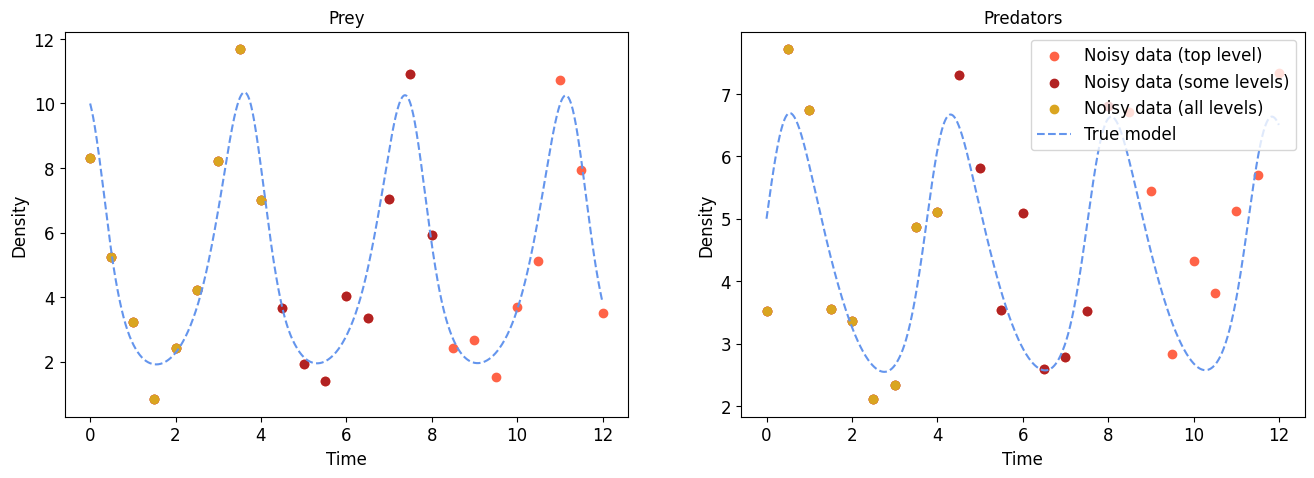

In [11]:
fig, axes = plt.subplots(figsize=(16,5), nrows=1, ncols=2)

axes[0].set_title('Prey', fontsize=12)
axes[0].plot(t_eval, y_true[:n_eval], '--', color='cornflowerblue')
axes[0].scatter(t_eval_l2, data_l2[:n_data_l2], color='tomato', label='Noisy data (top level)')
axes[0].scatter(t_eval_l1, data_l1[:n_data_l1], color='firebrick', label='Noisy data (some levels)')
axes[0].scatter(t_eval_l0, data_l0[:n_data_l0], color='goldenrod', label='Noisy data (all levels)')
axes[0].tick_params(axis='both', labelsize=12)
axes[0].set_xlabel('Time', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)

axes[1].set_title('Predators', fontsize=12)
axes[1].plot(t_eval, y_true[n_eval:], '--', color='cornflowerblue')
axes[1].scatter(t_eval_l2, data_l2[n_data_l2:], color='tomato', label='Noisy data (top level)')
axes[1].scatter(t_eval_l1, data_l1[n_data_l1:], color='firebrick', label='Noisy data (some levels)')
axes[1].scatter(t_eval_l0, data_l0[n_data_l0:], color='goldenrod', label='Noisy data (all levels)')
axes[1].plot([], [], '--', color='cornflowerblue', label = 'True model')
axes[1].tick_params(axis='both', labelsize=12)
axes[1].set_xlabel('Time', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].legend(loc=1, fontsize=12)
plt.show()

In [12]:
class LogTransformed:
    # the distribution of log(X), for a positive random variable X ~ dist
    def __init__(self, dist):
        self.dist = dist

    def logpdf(self, x):
        return self.dist.logpdf(np.exp(x)) + x

    def rvs(self, size=None):
        return np.log(self.dist.rvs(size=size))

# priors from the paper, on the parameters themselves
priors_all = [stats.norm(10.8, 1),
              stats.norm(5.3, 1),
              stats.norm(2.5, 0.5),
              stats.invgamma(1, scale=0.5),
              stats.invgamma(1, scale=0.5),
              stats.norm(1.2, 0.3)]

my_prior = tda.JointPrior([LogTransformed(priors_all[i]) for i in free])

In [13]:
# define the likelihood
cov_likelihood_l2 = sigma**2*np.eye(data_l2.size)
cov_likelihood_l1 = sigma**2*np.eye(data_l1.size)
cov_likelihood_l0 = sigma**2*np.eye(data_l0.size)

my_loglike_l2 = tda.GaussianLogLike(data_l2, cov_likelihood_l2)
my_loglike_l1 = tda.GaussianLogLike(data_l1, cov_likelihood_l1)
my_loglike_l0 = tda.GaussianLogLike(data_l0, cov_likelihood_l0)

In [14]:
# set up the link factories
my_posterior_l2 = tda.Posterior(my_prior, my_loglike_l2, my_model_l2)
my_posterior_l1 = tda.Posterior(my_prior, my_loglike_l1, my_model_l1)
my_posterior_l0 = tda.Posterior(my_prior, my_loglike_l0, my_model_l0)

my_posteriors = [my_posterior_l0, my_posterior_l1, my_posterior_l2]

In [15]:
# get the maximum a posteriori point on each level, starting from the true parameters so the result is
# the same every time
MAP = [tda.get_MAP(my_posteriors[l], initial_parameters=true_parameters, method='Nelder-Mead',
                   options={'xatol': 1e-8, 'fatol': 1e-10}) for l in range(3)]
for l in range(3):
    print(f'level {l} MAP: ' + '  '.join(f'{names[i]}={v:.4f}' for i, v in zip(free, np.exp(MAP[l]))))

level 0 MAP: a=3.1204  b=0.7558
level 1 MAP: a=2.9403  b=0.7060
level 2 MAP: a=2.9865  b=0.6854


In [17]:
# reference solution

if "CI" in os.environ:
    n_coarse, n_fine = 21, 31
else:
    n_coarse, n_fine = 41, 91

def evaluate(thetas, posteriors):
    # log-posterior and QoI of every posterior at every point
    links = [[p.create_link(t) for p in posteriors] for t in thetas]
    logpost = np.array([[link.posterior for link in row] for row in links])
    qoi = np.array([[link.qoi for link in row] for row in links])
    return np.where(np.isfinite(logpost), logpost, -np.inf), qoi

def grid(lo, hi, n):
    axes = [np.linspace(a, b, n) for a, b in zip(lo, hi)]
    return np.array(np.meshgrid(*axes, indexing='ij')).reshape(len(lo), -1).T

R = np.zeros((3, 3))         # R[l, k] = E_pi_l[Q_k]
theta_mean = np.zeros((3, len(free)))
theta_cov = np.zeros((3, len(free), len(free)))

for l in range(3):
    # coarse passes: start from a wide box around the MAP, then shrink it to the bounding box of
    # everything within 30 log-units of the maximum (about 7.7 standard deviations for a Gaussian)
    lo, hi = MAP[l] - 1.0, MAP[l] + 1.0
    for _ in range(3):
        thetas = grid(lo, hi, n_coarse)
        lp = np.array([my_posteriors[l].create_link(t).posterior for t in thetas])
        lp = np.where(np.isfinite(lp), lp, -np.inf)
        keep = thetas[lp > lp.max() - 30]
        step = (hi - lo) / (n_coarse - 1)
        lo, hi = keep.min(axis=0) - step, keep.max(axis=0) + step

    # fine pass on the final box
    thetas = grid(lo, hi, n_fine)
    logpost, qoi = evaluate(thetas, my_posteriors)

    # self-normalised weights for level l
    w = np.exp(logpost[:, l] - logpost[:, l].max())
    w /= w.sum()
    R[l] = w @ np.nan_to_num(qoi)
    theta_mean[l] = w @ thetas
    dev = thetas - theta_mean[l]
    theta_cov[l] = (w[:, None] * dev).T @ dev

    # how far the posterior has fallen at the edge of the box
    on_edge = np.any((thetas == lo) | (thetas == hi), axis=1)
    edge_drop = logpost[:, l].max() - logpost[on_edge, l].max()
    print(f'level {l}: mean ' + '  '.join(f'log {names[i]}={v:.4f}' for i, v in zip(free, theta_mean[l]))
          + f'   sd ' + '  '.join(f'{v:.4f}' for v in np.sqrt(np.diag(theta_cov[l])))
          + f'   edge drop {edge_drop:.0f}')

Q_ref = R[2, 2]
Q_state_limit = R[2, 2] + (R[0, 0] - R[1, 0]) + (R[1, 1] - R[2, 1])
print(f'\nR[l, k] = E_pi_l[Q_k]:\n{R}')
print(f'\nreference E_pi_2[Q_2]                    = {Q_ref:.6f}')
print(f'state-paired limit for J -> infinity       = {Q_state_limit:.6f}   (bias {Q_state_limit - Q_ref:+.4f})')

level 0: mean log a=1.1431  log b=-0.2781   sd 0.0368  0.0538   edge drop 30
level 1: mean log a=1.0803  log b=-0.3494   sd 0.0153  0.0403   edge drop 32
level 2: mean log a=1.0959  log b=-0.3827   sd 0.0099  0.0332   edge drop 30

R[l, k] = E_pi_l[Q_k]:
[[4.40300922 4.35785542 4.32013801]
 [4.37085633 4.33891873 4.32291046]
 [4.57614643 4.55732381 4.5431088 ]]

reference E_pi_2[Q_2]                    = 4.543109
state-paired limit for J -> infinity       = 4.356857   (bias -0.1863)


In [26]:
# random walk Metropolis
rwmh_cov = np.eye(2)
rmwh_scaling = 0.1
rwmh_adaptive = True
my_proposal = tda.GaussianRandomWalk(C=rwmh_cov, scaling=rmwh_scaling, adaptive=rwmh_adaptive)

In [24]:
if "CI" in os.environ:
    iterations = 150
    burnin = 50
    n_chains = 2
else:
    iterations = 2500
    burnin = 500
    n_chains = 1

subchain_length = 10

In [28]:
my_chains = tda.sample(my_posteriors, my_proposal, iterations=iterations, n_chains=n_chains,
                       initial_parameters=MAP[2], subchain_length=subchain_length,
                       randomize_subchain_length=True)

Sampling chain 1/1


Running chain, α = 0.13: 100%|██████████| 2500/2500 [12:46<00:00,  3.26it/s]


In [29]:
idata = tda.to_inference_data(my_chains, level=2, burnin=burnin, parameter_names=[f'log_{names[i]}' for i in free])
az.summary(idata)

/Users/louisekluge/mlda-variance-reduction/.pixi/envs/default/lib/python3.11/site-packages/arviz/data/inference_data.py:157: UserWarning: qoi group is not defined in the InferenceData scheme
  warnings.warn(
arviz - WARNING - Shape validation failed: input_shape: (1, 2001), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
log_a,1.095,0.010,1.074,1.109,0.001,0.001,166.0,101.0,NaN
log_b,-0.375,0.034,-0.450,-0.318,0.005,0.004,42.0,43.0,NaN


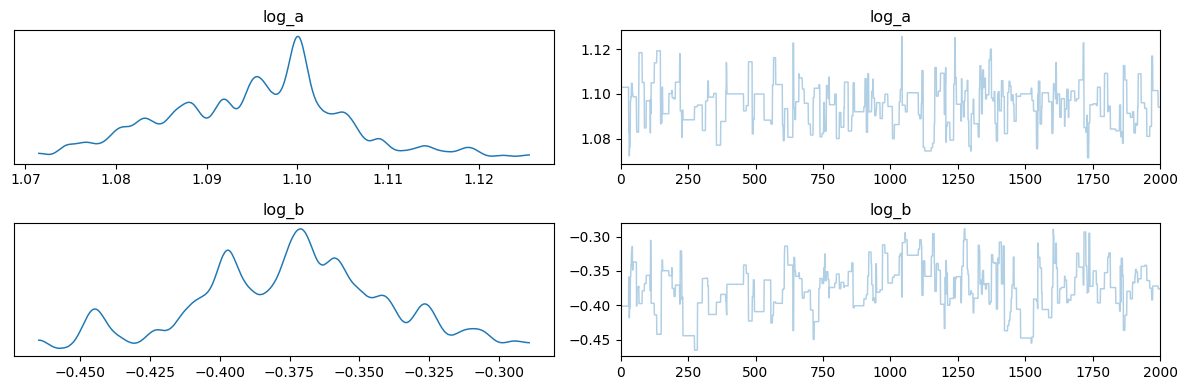

In [30]:
az.plot_trace(idata)
plt.tight_layout()
plt.show()

In [31]:
mlqoi = tda.get_multilevel_inference_data(my_chains, attribute='qoi', burnin=burnin)
mlpar = tda.get_multilevel_inference_data(my_chains, attribute='parameters', burnin=burnin)

In [32]:
def state_paired_coarse_qoi(fine_parameters, promoted_parameters, promoted_qoi, coarse_posterior):
    # Q_{l-1} at the fine states, looked up among the promoted samples
    lookup = {p.tobytes(): q for p, q in zip(promoted_parameters, promoted_qoi)}
    out = np.empty(len(fine_parameters))
    for n, p in enumerate(fine_parameters):
        key = p.tobytes()
        if key not in lookup:
            lookup[key] = coarse_posterior.create_link(p).qoi
        out[n] = lookup[key]
    return out

def terms(i):
    # the coarsest-level QoI and the two kinds of correction for chain i
    out = {'Q_top': mlqoi['chains'][f'level2_chain{i}'][:, 0],
           'Q_0': mlqoi['chains'][f'level0_chain{i}'][:, 0],
           'proposal': [], 'state': []}
    for l in (1, 2):
        fine_q = mlqoi['chains'][f'level{l}_chain{i}'][:, 0]
        prom_q = mlqoi['promoted'][f'level{l-1}_chain{i}'][:, 0]
        fine_p = mlpar['chains'][f'level{l}_chain{i}']
        prom_p = mlpar['promoted'][f'level{l-1}_chain{i}']

        out['proposal'].append(fine_q - prom_q)

        coarse_q = state_paired_coarse_qoi(fine_p, prom_p, prom_q, my_posteriors[l-1])
        out['state'].append(fine_q - coarse_q)
    return out

my_terms = [terms(i) for i in range(n_chains)]

for l in (1, 2):
    pairs = np.mean([np.mean(np.all(mlpar['chains'][f'level{l}_chain{i}'] == mlpar['promoted'][f'level{l-1}_chain{i}'], axis=1))
                     for i in range(n_chains)])
    print(f'Y_{l}{l-1}: {pairs:.1%} of proposal-paired pairs sit at a common parameter value')

Y_10: 35.9% of proposal-paired pairs sit at a common parameter value
Y_21: 69.8% of proposal-paired pairs sit at a common parameter value


In [33]:
def ess(x):
    return float(az.ess(np.asarray(x)[None, :]))

def head(x, fraction):
    return x[:max(8, int(round(fraction * len(x))))]

def along_run(t, n_samples):
    n_top = len(t['Q_top'])
    rows = {k: [] for k in ('standard', 'proposal', 'state', 'se_standard', 'se_proposal', 'se_state')}
    for n in n_samples:
        f = n / n_top
        top = head(t['Q_top'], f)
        rows['standard'].append(top.mean())
        rows['se_standard'].append(np.sqrt(top.var() / ess(top)))
        q0 = head(t['Q_0'], f)
        for kind in ('proposal', 'state'):
            ys = [head(y, f) for y in t[kind]]
            rows[kind].append(q0.mean() + sum(y.mean() for y in ys))
            rows[f'se_{kind}'].append(np.sqrt(q0.var() / ess(q0) + sum(y.var() / ess(y) for y in ys)))
    return {k: np.array(v) for k, v in rows.items()}

n_top = len(my_terms[0]['Q_top'])
n_samples = np.unique(np.geomspace(min(200, n_top // 2), n_top, 15).astype(int))
curves = [along_run(t, n_samples) for t in my_terms]

mean_se = {k: np.mean([c[f'se_{k}'] for c in curves], axis=0) for k in ('standard', 'proposal', 'state')}
estimates = {k: np.array([c[k] for c in curves]) for k in ('standard', 'proposal', 'state')}
rmse = {k: np.sqrt(np.mean((v - Q_ref)**2, axis=0)) for k, v in estimates.items()}
bias = {k: np.mean(v - Q_ref, axis=0) for k, v in estimates.items()}

print(f'{"N":>6}' + ''.join(f'{k + " SE":>15}' for k in mean_se) + ''.join(f'{k + " RMSE":>15}' for k in rmse))
for j, n in enumerate(n_samples):
    print(f'{n:6d}' + ''.join(f'{mean_se[k][j]:15.5f}' for k in mean_se) + ''.join(f'{rmse[k][j]:15.5f}' for k in rmse))

     N    standard SE    proposal SE       state SE  standard RMSE  proposal RMSE     state RMSE
   200        0.04691        0.03627        0.00606        0.00326        0.01028        0.12949
   235        0.04037        0.03056        0.00553        0.00143        0.00557        0.12997
   277        0.04265        0.03086        0.00598        0.03784        0.04157        0.11462
   327        0.03949        0.03146        0.00522        0.03548        0.04028        0.11486
   386        0.03684        0.03203        0.00509        0.03704        0.04078        0.11091
   455        0.03312        0.02822        0.00497        0.02716        0.03112        0.11444
   536        0.02597        0.02315        0.00382        0.03092        0.03330        0.11371
   632        0.02764        0.02291        0.00370        0.01833        0.01855        0.11705
   745        0.02558        0.02118        0.00360        0.01556        0.01735        0.11604
   878        0.02357        0

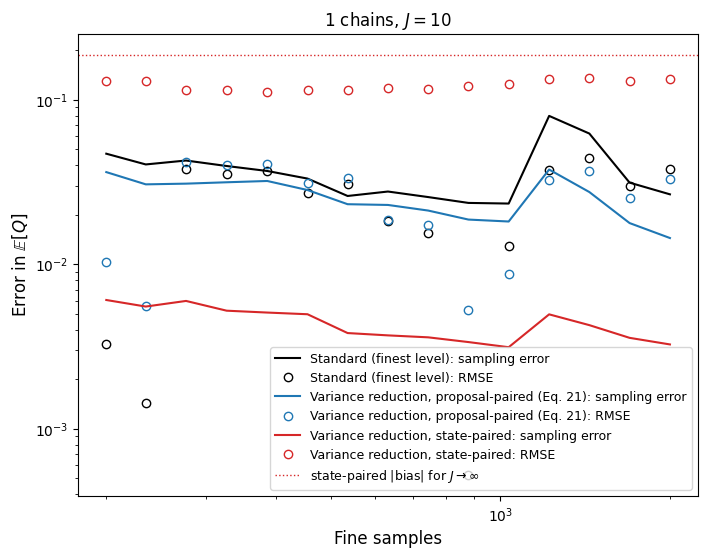

In [34]:
style = {'standard': ('k', 'Standard (finest level)'),
         'proposal': ('tab:blue', 'Variance reduction, proposal-paired (Eq. 21)'),
         'state': ('tab:red', 'Variance reduction, state-paired')}

fig, ax = plt.subplots(figsize=(8, 6))
for k, (color, label) in style.items():
    ax.loglog(n_samples, mean_se[k], '-', color=color, label=f'{label}: sampling error')
    ax.loglog(n_samples, rmse[k], 'o', color=color, mfc='none', label=f'{label}: RMSE')
ax.axhline(abs(Q_state_limit - Q_ref), color='tab:red', ls=':', lw=1,
           label='state-paired |bias| for $J \\to \\infty$')
ax.set_xlabel('Fine samples', fontsize=12)
ax.set_ylabel('Error in $\\mathbb{E}[Q]$', fontsize=12)
ax.set_title(f'{n_chains} chains, $J = {subchain_length}$', fontsize=12)
ax.legend(fontsize=9)
plt.show()

In [35]:
print(f'reference                     {Q_ref:.5f}')
for k in ('standard', 'proposal', 'state'):
    final = estimates[k][:, -1]
    print(f'{k:9s} final estimate  {final.mean():.5f} +- {final.std(ddof=1) / np.sqrt(n_chains):.5f}'
          f'   bias {bias[k][-1]:+.5f}')

reference                     4.54311
standard  final estimate  4.50522 +- nan   bias -0.03789
proposal  final estimate  4.51004 +- nan   bias -0.03307
state     final estimate  4.40973 +- nan   bias -0.13338


/Users/louisekluge/mlda-variance-reduction/.pixi/envs/default/lib/python3.11/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/louisekluge/mlda-variance-reduction/.pixi/envs/default/lib/python3.11/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
